## INTEGRANTES
- Guilherme Nunes – 558989
- Kaique Zaffarani – 556677
- Kairo Silvestre – 558288
- Pedro Josué – 554913

## Importação de bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve

# Parte A - Análise Exploratória, Validação Cruzada, Lasso e Ridge

## 1. Preparação e Análise Exploratória

In [2]:
URL = "https://raw.githubusercontent.com/primaryobjects/voice-gender/master/voice.csv"
df = pd.read_csv(URL)

print(f"Shape: {df.shape}")
df.head()

Shape: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
# Codificar alvo: 'female' -> 0, 'male' -> 1
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])

# Separar features (X) e alvo (y)
X = df.drop(columns=['label', 'label_enc'])
y = df['label_enc']

print(f"X: {X.shape}, y: {y.shape}")

X: (3168, 20), y: (3168,)


Contagem:
label
male      1584
female    1584
Name: count, dtype: int64

Proporção (%):
label
male      50.0
female    50.0
Name: proportion, dtype: float64


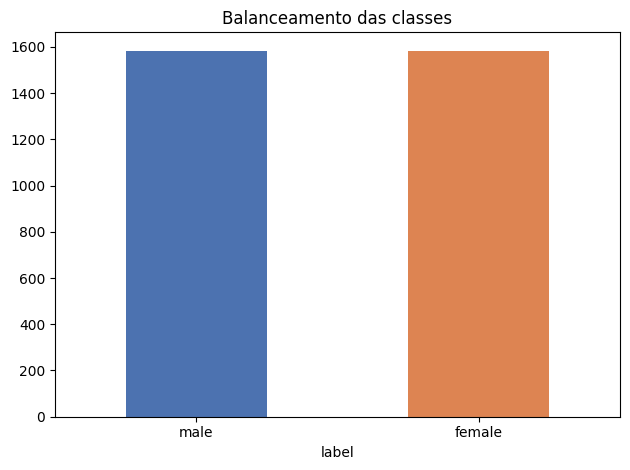

In [4]:
# Proporção das classes (balanceamento do alvo)
contagem = df['label'].value_counts()
proporcao = df['label'].value_counts(normalize=True) * 100

print("Contagem:")
print(contagem)
print("\nProporção (%):")
print(proporcao.round(2))

contagem.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.title('Balanceamento das classes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

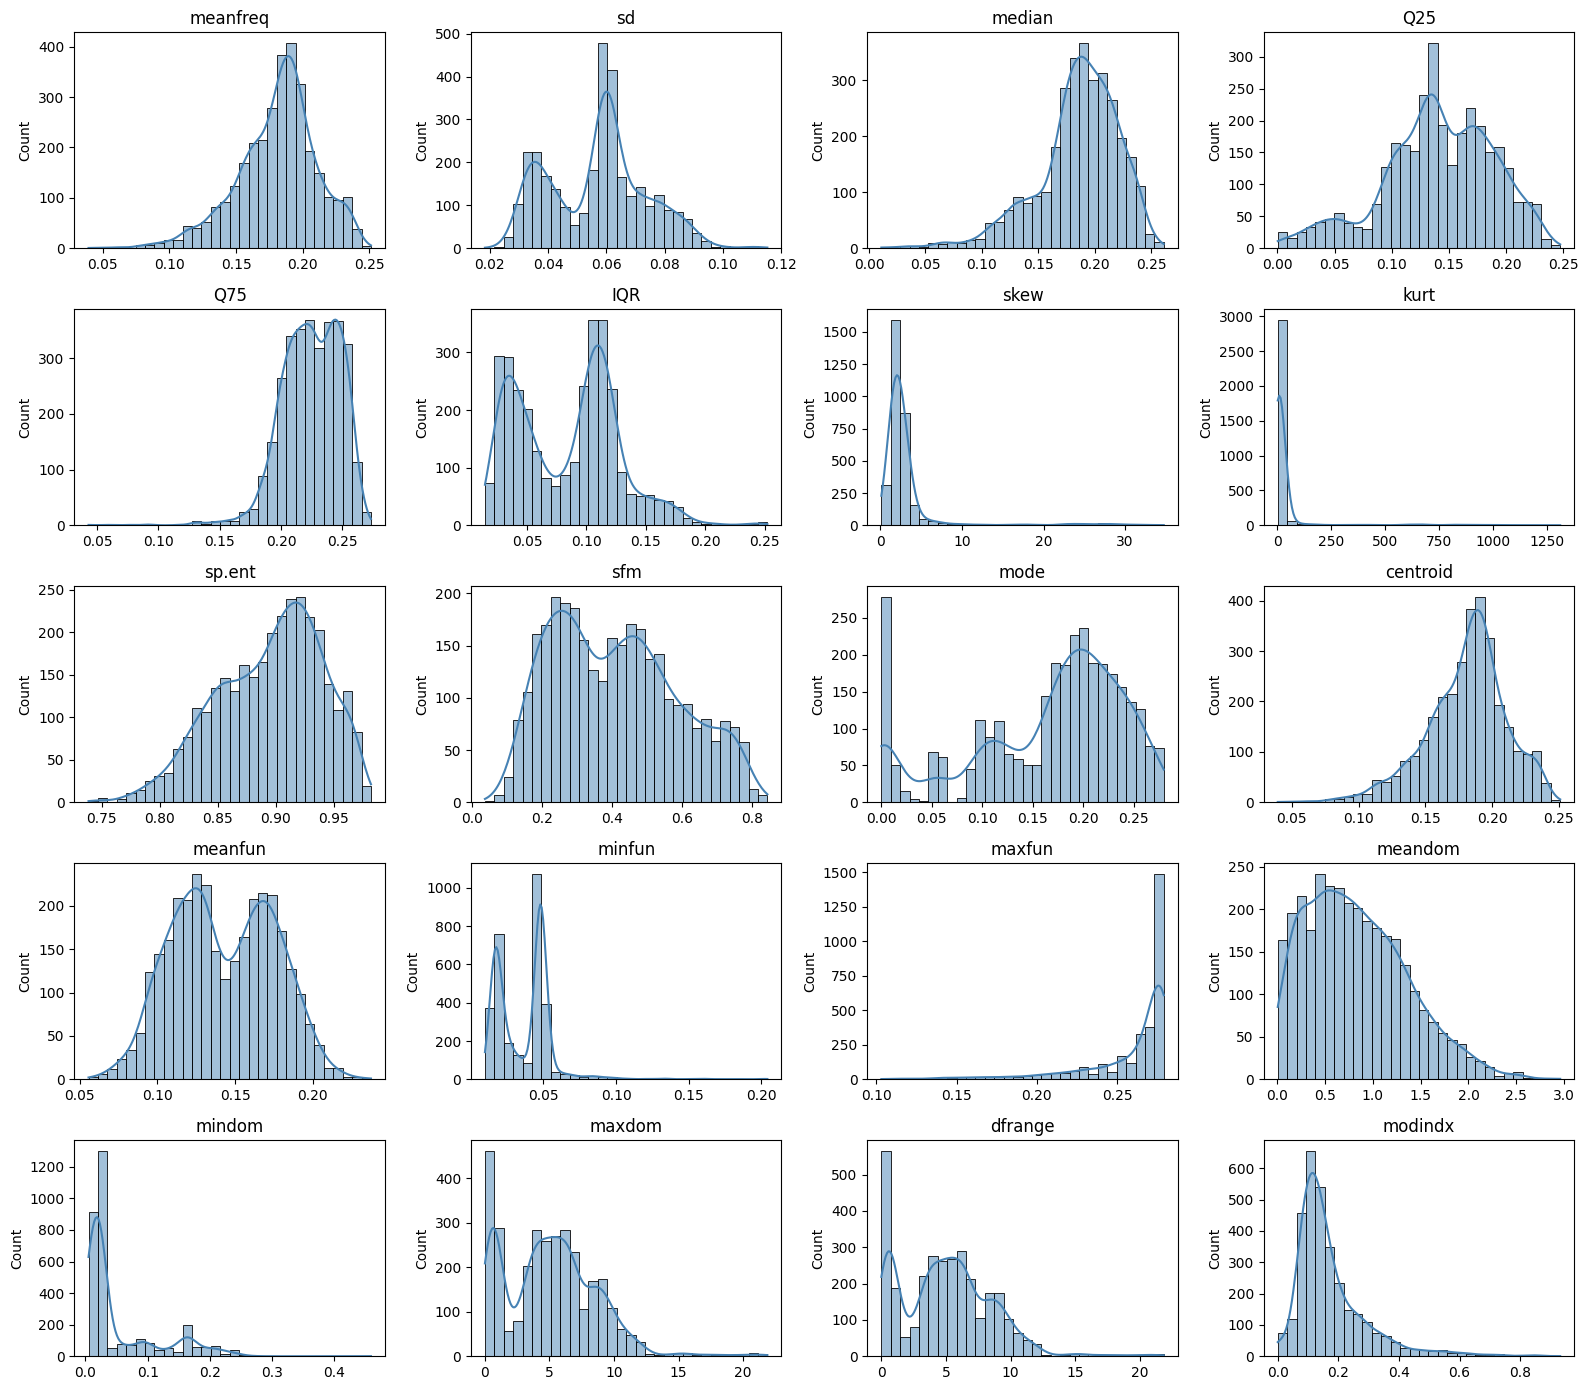

In [5]:
# Distribuição de cada feature: histograma + densidade
fig, axes = plt.subplots(5, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(X.columns):
    sns.histplot(X[col], bins=30, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# Esconder subplots vazios
for j in range(len(X.columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

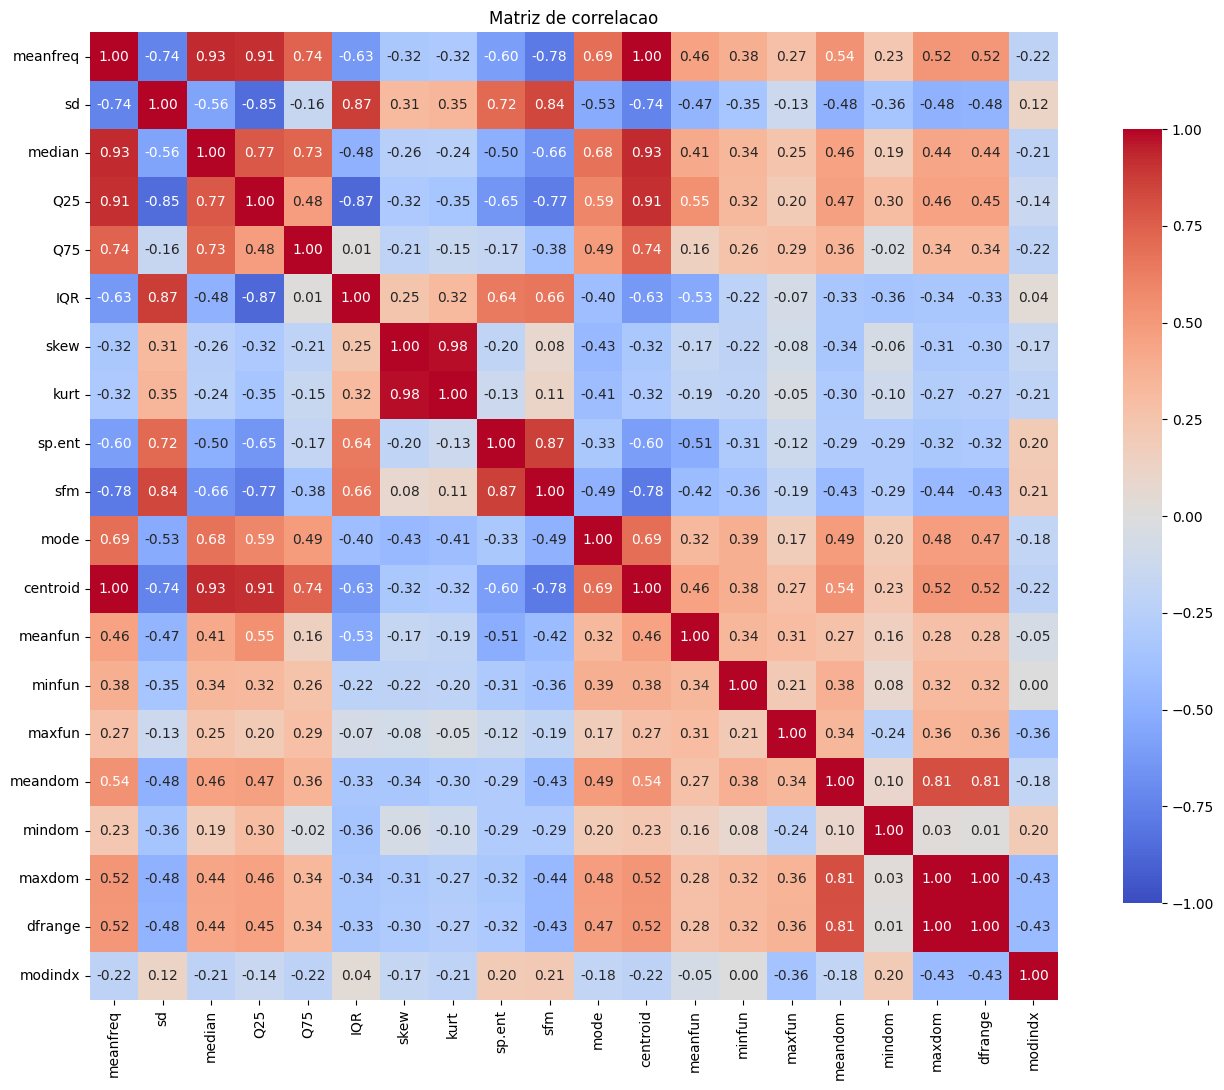

In [6]:
# Matriz de correlação entre as features
corr = X.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlacao')
plt.tight_layout()
plt.show()

In [7]:
# Identificar pares com correlação alta (|r| >= 0.85)
LIMIAR = 0.85
pares = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        v = corr.iloc[i, j]
        if abs(v) >= LIMIAR:
            pares.append((corr.columns[i], corr.columns[j], round(v, 3)))

print(f"Pares com |correlacao| >= {LIMIAR}:")
for f1, f2, v in pares:
    print(f"  {f1:<12} <-> {f2:<12}  r = {v}")

Pares com |correlacao| >= 0.85:
  meanfreq     <-> median        r = 0.925
  meanfreq     <-> Q25           r = 0.911
  meanfreq     <-> centroid      r = 1.0
  sd           <-> IQR           r = 0.875
  median       <-> centroid      r = 0.925
  Q25          <-> IQR           r = -0.874
  Q25          <-> centroid      r = 0.911
  skew         <-> kurt          r = 0.977
  sp.ent       <-> sfm           r = 0.866
  maxdom       <-> dfrange       r = 1.0


**Discussão - multicolinearidade**

1. Coeficientes da regressão logística ficam instáveis e difíceis de interpretar individualmente.
2. O erro padrão dos coeficientes aumenta, prejudicando testes de significância.
3. Features redundantes não adicionam informação nova, só ruído.
4. O modelo pode dar peso quase igual a variáveis que medem a mesma coisa, em vez de concentrar a importância.

Soluções: regularização (L1 zera redundantes, L2 distribui o peso) ou remoção manual de uma das features de cada par muito correlacionado.

In [8]:
# Amplitude (max - min) de cada feature
amplitudes = (X.max() - X.min()).sort_values(ascending=False)
print("Amplitude por feature:")
print(amplitudes.round(4))

Amplitude por feature:
kurt        1307.5444
skew          34.5837
maxdom        21.8594
dfrange       21.8438
meandom        2.9499
modindx        0.9324
sfm            0.8061
mindom         0.4541
mode           0.2800
median         0.2502
Q25            0.2471
sp.ent         0.2433
IQR            0.2377
Q75            0.2305
centroid       0.2118
meanfreq       0.2118
minfun         0.1943
meanfun        0.1821
maxfun         0.1760
sd             0.0969
dtype: float64


**Discussão - escalas e padronização**

As features estão em escalas muito diferentes (algumas abaixo de 0.1, outras na ordem de dezenas). Sem padronização, a regularização penaliza injustamente as features de maior magnitude. O `StandardScaler` transforma cada feature em média 0 e desvio 1, garantindo tratamento equivalente.


## 2. Grid Search com Validação Cruzada

In [9]:
# Split treino/teste (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")

Treino: (2534, 20) | Teste: (634, 20)


In [10]:
# GridSearchCV: testar L1/L2 com vários C usando 5-fold CV
modelo_base = LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)

# Grade ampliada de C: cobre desde regularização muito forte (0.001) até praticamente sem regularização (1000)
param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100, 500, 1000]
}

grid = GridSearchCV(
    estimator=modelo_base,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=1000, random_state=42,
                                          solver='liblinear'),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100,
                               500, 1000],
                         'penalty': ['l1', 'l2']},
             return_train_score=True, scoring='accuracy')

In [11]:
# Reportar a combinação de parâmetros com melhor desempenho médio de validação
print("=" * 60)
print("MELHOR COMBINAÇÃO DE PARÂMETROS")
print("=" * 60)
print(f"Penalização: {grid.best_params_['penalty']}")
print(f"C:           {grid.best_params_['C']}")
print(f"Acurácia média (validação cruzada k=5): {grid.best_score_:.4f}")
print("=" * 60)

# Tabela com todas as combinações ordenadas pela acurácia média de validação
resultados = pd.DataFrame(grid.cv_results_)
tabela = resultados[['param_penalty', 'param_C', 'mean_test_score', 'std_test_score']]
tabela = tabela.sort_values('mean_test_score', ascending=False).reset_index(drop=True)
tabela.columns = ['penalty', 'C', 'acc_val_media', 'acc_val_desvio']
tabela.round(4)

MELHOR COMBINAÇÃO DE PARÂMETROS
Penalização: l1
C:           0.5
Acurácia média (validação cruzada k=5): 0.9716


,penalty,C,acc_val_media,acc_val_desvio
0,l1,0.500,0.9716,0.0051
1,l2,0.500,0.9712,0.0044
2,l2,0.100,0.9708,0.0074
3,l2,1.000,0.9708,0.0050
4,l1,5.000,0.9704,0.0048
5,l2,10.000,0.9704,0.0048
6,l2,5.000,0.9704,0.0048
7,l1,10.000,0.9704,0.0048
8,l2,50.000,0.9700,0.0053
9,l1,1.000,0.9700,0.0042


## 3. Modelo Final

In [12]:
# Modelo final já reajustado pelo GridSearchCV
melhor_modelo = grid.best_estimator_

# Predições no conjunto de teste
y_pred = melhor_modelo.predict(X_test_scaled)
y_proba = melhor_modelo.predict_proba(X_test_scaled)[:, 1]

# Métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Métricas no conjunto de teste:")
print(f"  Acurácia : {acc:.4f}")
print(f"  Precisão : {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1-score : {f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Métricas no conjunto de teste:
  Acurácia : 0.9732
  Precisão : 0.9630
  Recall   : 0.9842
  F1-score : 0.9735

Classification report:
              precision    recall  f1-score   support

      female       0.98      0.96      0.97       317
        male       0.96      0.98      0.97       317

    accuracy                           0.97       634
   macro avg       0.97      0.97      0.97       634
weighted avg       0.97      0.97      0.97       634



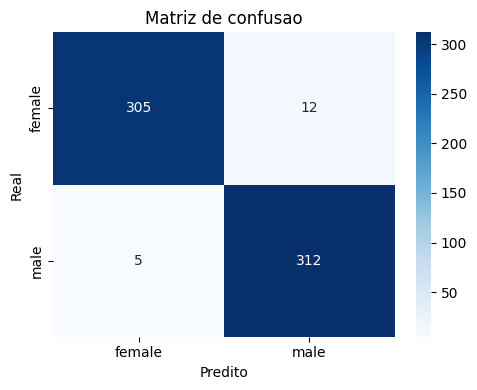

In [13]:
# Matriz de confusão no conjunto de teste
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matriz de confusao')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

## 4. Discussão

In [14]:
# Treinar L1 e L2 com o mesmo C para comparar coeficientes
melhor_C = grid.best_params_['C']

modelo_l1 = LogisticRegression(penalty='l1', C=melhor_C, solver='liblinear', max_iter=1000, random_state=42)
modelo_l2 = LogisticRegression(penalty='l2', C=melhor_C, solver='liblinear', max_iter=1000, random_state=42)

modelo_l1.fit(X_train_scaled, y_train)
modelo_l2.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    'feature': X.columns,
    'coef_L1': modelo_l1.coef_[0],
    'coef_L2': modelo_l2.coef_[0]
})
coef_df = coef_df.reindex(coef_df['coef_L1'].abs().sort_values(ascending=False).index)
coef_df = coef_df.reset_index(drop=True)
coef_df.round(4)

,feature,coef_L1,coef_L2
0,meanfun,-4.8930,-4.4824
1,IQR,2.2277,1.2391
2,sfm,-1.2981,-1.2925
3,sp.ent,1.1796,1.1384
4,minfun,0.5330,0.4957
5,modindx,-0.3463,-0.3562
6,kurt,-0.3076,-0.2827
7,skew,-0.2698,-0.2615
8,meandom,0.0916,0.1137
9,Q75,0.0835,0.6127


In [15]:
# Quais features o Lasso (L1) eliminou?
features_eliminadas = coef_df[coef_df['coef_L1'] == 0]['feature'].tolist()
features_mantidas = coef_df[coef_df['coef_L1'] != 0]['feature'].tolist()

print(f"Features ELIMINADAS pelo L1 ({len(features_eliminadas)}):")
print(f"  {features_eliminadas if features_eliminadas else 'Nenhuma'}")
print(f"\nFeatures MANTIDAS pelo L1 ({len(features_mantidas)}):")
print(f"  {features_mantidas}")

# Comparar com L2
n_l2_quase_zero = (coef_df['coef_L2'].abs() < 0.01).sum()
print(f"\nL2: {n_l2_quase_zero} coeficientes com |coef| < 0.01 (encolhidos, mas não zerados)")

Features ELIMINADAS pelo L1 (7):
  ['median', 'sd', 'meanfreq', 'Q25', 'centroid', 'maxfun', 'maxdom']

Features MANTIDAS pelo L1 (13):
  ['meanfun', 'IQR', 'sfm', 'sp.ent', 'minfun', 'modindx', 'kurt', 'skew', 'meandom', 'Q75', 'mode', 'mindom', 'dfrange']

L2: 2 coeficientes com |coef| < 0.01 (encolhidos, mas não zerados)


**Qual a diferença entre os coeficientes L1 e L2?**
L1 zera completamente os coeficientes de algumas features (seleção de variáveis). L2 mantém todos os coeficientes, apenas reduz a magnitude proporcionalmente.

**Quais variáveis foram eliminadas pelo Lasso?**
As listadas acima como "ELIMINADAS pelo L1". São features pouco informativas ou redundantes em relação a outras.

**Qual o efeito da regularização no desempenho?**
Reduz overfitting ao penalizar coeficientes grandes. Em datasets com multicolinearidade, melhora a estabilidade do modelo.

**Qual o efeito na interpretabilidade?**
L1 produz modelo mais simples (menos features), facilitando interpretação. L2 mantém todas as features, dificultando identificar quais são mais importantes.

**Quando usar L1 vs L2?**
L1 quando suspeita-se de muitas features irrelevantes ou quer-se seleção automática. L2 quando todas as features são relevantes e quer-se modelo estável.

# Parte B - Alterando a Função de Perda

## 1. Experimento

In [16]:
# Implementação regressão logística que minimiza RMSE em vez de log-loss.
# Treinamento por gradiente descendente.

class LogisticRegressionRMSE:

    def __init__(self, lr=0.05, n_iter=3000, random_state=42):
        self.lr = lr                   # taxa de aprendizado
        self.n_iter = n_iter           # número de iterações
        self.random_state = random_state
        self.losses_ = []              # histórico do RMSE

    @staticmethod
    def _sigmoid(z):
        # Sigmoid com clip para evitar overflow numérico
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n_samples, n_features = X.shape

        # Inicializar pesos pequenos
        self.w = rng.normal(0, 0.01, n_features)
        self.b = 0.0
        y = y.astype(float)

        for _ in range(self.n_iter):
            # Forward: z = w*x + b, p = sigmoid(z)
            z = X @ self.w + self.b
            p = self._sigmoid(z)

            # Erro e RMSE
            erro = p - y
            mse = np.mean(erro ** 2)
            rmse = np.sqrt(mse + 1e-12)
            self.losses_.append(rmse)

            # Gradiente do RMSE em relação a w e b (regra da cadeia via sigmoid)
            grad_mse_w = (2.0 / n_samples) * (X.T @ (erro * p * (1.0 - p)))
            grad_mse_b = (2.0 / n_samples) * np.sum(erro * p * (1.0 - p))

            self.w -= self.lr * (grad_mse_w / (2.0 * rmse))
            self.b -= self.lr * (grad_mse_b / (2.0 * rmse))

        return self

    def predict_proba(self, X):
        p1 = self._sigmoid(X @ self.w + self.b)
        return np.vstack([1 - p1, p1]).T

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

print("Classe LogisticRegressionRMSE definida.")

Classe LogisticRegressionRMSE definida.


In [17]:
# Treinar o modelo RMSE com os mesmos dados padronizados
modelo_rmse = LogisticRegressionRMSE(lr=0.05, n_iter=3000, random_state=42)
modelo_rmse.fit(X_train_scaled, y_train.values)

y_pred_rmse = modelo_rmse.predict(X_test_scaled)
y_proba_rmse = modelo_rmse.predict_proba(X_test_scaled)[:, 1]

# Acurácia no teste
acc_rmse = accuracy_score(y_test, y_pred_rmse)
print(f"Acuracia RMSE: {acc_rmse:.4f}")

Acuracia RMSE: 0.9732


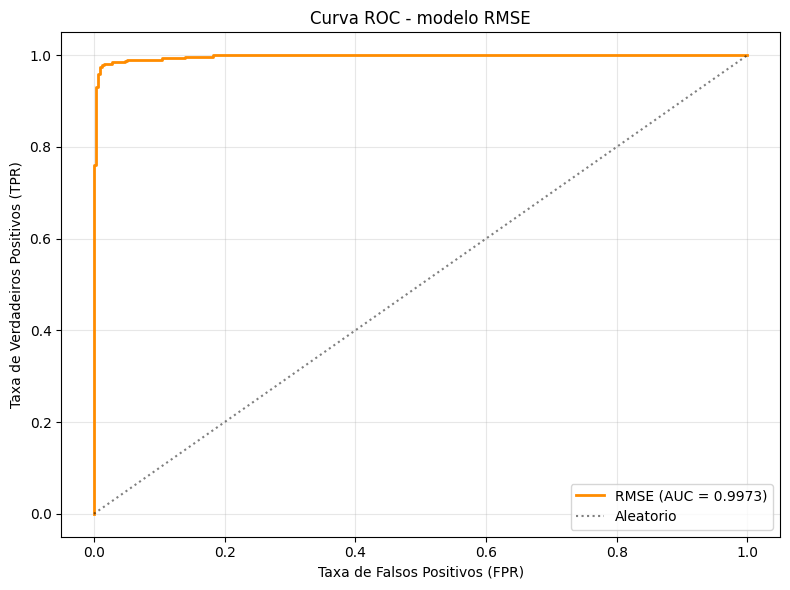

In [18]:
# Curva ROC do modelo RMSE no conjunto de teste
fpr_rmse, tpr_rmse, _ = roc_curve(y_test, y_proba_rmse)
auc_rmse = auc(fpr_rmse, tpr_rmse)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rmse, tpr_rmse, label=f'RMSE (AUC = {auc_rmse:.4f})',
         linewidth=2, color='darkorange')
plt.plot([0, 1], [0, 1], 'k:', alpha=0.5, label='Aleatorio')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - modelo RMSE')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Comparação

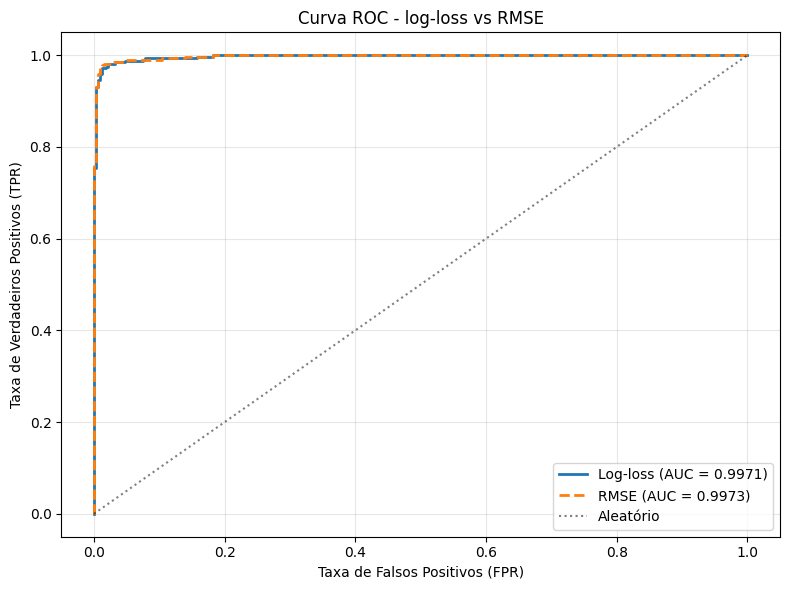

In [19]:
# Comparação com o modelo log-loss da Parte A
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba)
auc_log = auc(fpr_log, tpr_log)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log, tpr_log, label=f'Log-loss (AUC = {auc_log:.4f})', linewidth=2)
plt.plot(fpr_rmse, tpr_rmse, label=f'RMSE (AUC = {auc_rmse:.4f})',
         linewidth=2, linestyle='--')
plt.plot([0, 1], [0, 1], 'k:', alpha=0.5, label='Aleatório')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - log-loss vs RMSE')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Tabela comparativa de métricas
def metricas(y_true, y_pred, y_proba):
    return {
        'Acurácia': accuracy_score(y_true, y_pred),
        'Precisão': precision_score(y_true, y_pred),
        'Recall':   recall_score(y_true, y_pred),
        'F1':       f1_score(y_true, y_pred),
        'AUC':      roc_auc_score(y_true, y_proba),
    }

resumo = pd.DataFrame({
    'Log-loss': metricas(y_test, y_pred, y_proba),
    'RMSE':     metricas(y_test, y_pred_rmse, y_proba_rmse),
}).round(4)

resumo

,Log-loss,RMSE
Acurácia,0.9732,0.9732
Precisão,0.9630,0.9630
Recall,0.9842,0.9842
F1,0.9735,0.9735
AUC,0.9971,0.9973


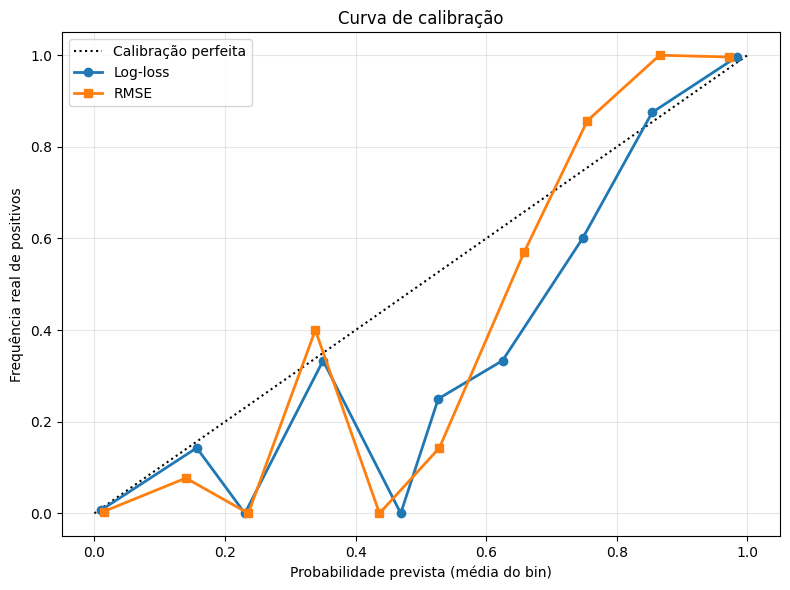

In [21]:
# Curva de calibração (decisão)
prob_true_log, prob_pred_log = calibration_curve(y_test, y_proba, n_bins=10)
prob_true_rmse, prob_pred_rmse = calibration_curve(y_test, y_proba_rmse, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], 'k:', label='Calibração perfeita')
plt.plot(prob_pred_log, prob_true_log, marker='o', linewidth=2, label='Log-loss')
plt.plot(prob_pred_rmse, prob_true_rmse, marker='s', linewidth=2, label='RMSE')
plt.xlabel('Probabilidade prevista (média do bin)')
plt.ylabel('Frequência real de positivos')
plt.title('Curva de calibração')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

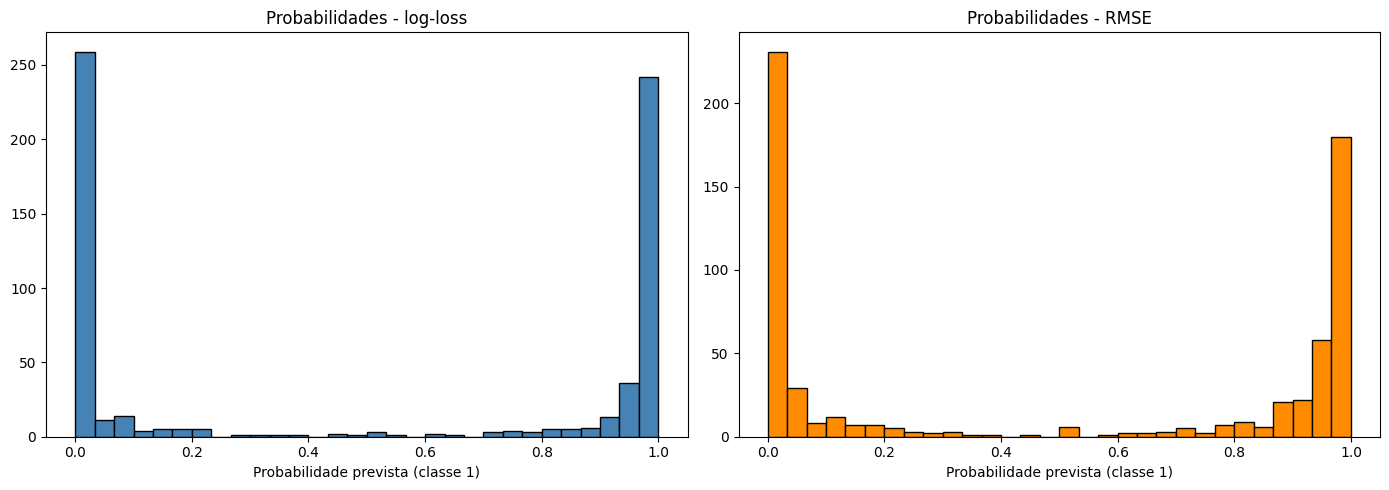

In [22]:
# Distribuição das probabilidades preditas pelos dois modelos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y_proba, bins=30, color='steelblue', edgecolor='black')
axes[0].set_title('Probabilidades - log-loss')
axes[0].set_xlabel('Probabilidade prevista (classe 1)')

axes[1].hist(y_proba_rmse, bins=30, color='darkorange', edgecolor='black')
axes[1].set_title('Probabilidades - RMSE')
axes[1].set_xlabel('Probabilidade prevista (classe 1)')

plt.tight_layout()
plt.show()

## 3. Discussão Crítica

**Por que RMSE é uma escolha ruim para regressão logística?**
A regressão logística produz probabilidades (entre 0 e 1), não valores contínuos. RMSE foi pensado para regressão com valores contínuos.

**Como cada perda trata um erro de alta confiança?**
Se o modelo prevê 0.99 para a classe errada:
- RMSE contribui com (0.99 - 0)^2 = 0.98 (limitado a no máximo 1).
- Log-loss contribui com -log(0.01) = 4.6 (vai a infinito conforme a confiança cresce).
Log-loss pune muito mais erros confiantes.

**Qual o problema de otimização?**
Log-loss aplicada à regressão logística é convexa, garante mínimo global único. RMSE aplicada sobre sigmoid é não-convexa, pode ter mínimos locais e converge mais devagar.

**O que acontece com a qualidade das probabilidades quando trocamos log-loss por RMSE?**
As probabilidades ficam mal calibradas - tendem a se concentrar perto de 0.5, o modelo perde "confiança". Uma probabilidade de 0.7 do modelo RMSE não significa que o evento ocorre 70% das vezes.

**A acurácia e o AUC mudam muito?**
Geralmente não - o ranking das probabilidades é parecido, então decisões binárias funcionam. O problema está nas probabilidades em si, não na classificação.

**Quando isso importa na prática?**
Sempre que se precisa da probabilidade em si: precificação de risco, triagem médica, decisões baseadas em limiar customizado, cálculo de valor esperado.

# Conclusão

O dataset Voice Gender Recognition está perfeitamente balanceado, dispensando técnicas de balanceamento. A análise exploratória identificou multicolinearidade entre várias features acústicas (com correlações acima de 0.85) e escalas muito diferentes entre as variáveis, justificando a aplicação do `StandardScaler` antes do treinamento.

Na busca em grade com validação cruzada k=5, foram testadas combinações de penalização L1 e L2 com 12 valores diferentes de C. A melhor combinação foi reportada via `grid.best_params_`, com a acurácia média de validação correspondente.

Na comparação entre L1 (Lasso) e L2 (Ridge), o Lasso zerou completamente alguns coeficientes, atuando como seletor de variáveis e produzindo um modelo mais interpretável. O Ridge apenas reduziu a magnitude dos coeficientes, mantendo todas as features ativas - útil quando todas contribuem e o objetivo é estabilidade.

Na Parte B, a substituição da log-loss por RMSE manteve a acurácia e o AUC em mesmo níveis, já que o ranking das probabilidades é preservado. No entanto, a curva de calibração mostrou que o modelo treinado com RMSE produz probabilidades ligeiramente menos calibradas, com desvios mais frequentes da diagonal de calibração perfeita. Log-loss é a função de perda correta para regressão logística, porque deriva da máxima verossimilhança da Bernoulli e penaliza fortemente erros de alta confiança, garantindo probabilidades interpretáveis.

Em datasets normalizados com modelos lineares simples, esse impacto pode ser pequeno na prática — como observado nos resultados equivalentes entre os modelos. No entanto, o problema se torna mais relevante quando as probabilidades são usadas como estimativa de risco real, não apenas para classificação. Nesses contextos, como diagnóstico médico ou score de crédito, a diferença na calibração deixa de ser marginal e passa a ter consequências diretas na tomada de decisão.

É a diferença entre perguntar "vai ocorrer ou não?" e "qual a chance de ocorrer?". Para a primeira, os dois modelos são equivalentes. Para a segunda, apenas o log loss garante uma resposta confiável.
